# Assignment 1 Programming
Data: CIFA-10
1. Implement Softmax Regression
2. Implement Convolutional Neural Networks depth 2, 8, 16, 32
3. Deep base model depth 16 with dropout and weight decay
4. Learning rate variation effects
5. Mini-batch Size effects


## 1.1 Import and device control

In [2]:
import torch
from d2l import torch as d2l
import torchvision
from torch.utils.data import random_split, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
import time
import torch.nn.functional as F
import torch.nn as nn
import pandas as pd
import random
import numpy as np

/opt/miniconda3/envs/d2l/lib/python3.9/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'dlopen(/opt/miniconda3/envs/d2l/lib/python3.9/site-packages/torchvision/image.so, 0x0006): Symbol not found: __ZN3c1017RegisterOperatorsD1Ev
  Referenced from: <00B86D22-833F-3522-B9CF-FCA5ED5567DC> /opt/miniconda3/envs/d2l/lib/python3.9/site-packages/torchvision/image.so
  Expected in:     <B6BD92AE-4D03-3F92-9E03-2E2594A12866> /opt/miniconda3/envs/d2l/lib/python3.9/site-packages/torch/lib/libtorch_cpu.dylib'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(


In [40]:
#My macbook could use mps but kernal died everytime. I left an option for cuda instead
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Using device:", device)

Using device: cpu


## 2.1 Graph functions

In [3]:
#function for fixed seed
def set_seed(seed=22):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
set_seed()

In [4]:
#unnormalize so matplotlib does not cause clipping data error
def denormalize(img):
    mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
    std = torch.tensor([0.2023, 0.1994, 0.2010]).view(3, 1, 1)
    return img * std + mean

# def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5):
#     figsize = (num_cols * scale, num_rows * scale)
#     fig, axes = plt.subplots(num_rows, num_cols, figsize=figsize)
#     axes = axes.flatten()

#     for i, (ax, img) in enumerate(zip(axes, imgs)):
#         if img.shape[0] == 3:  # RGB image
            # img = img.permute(1, 2, 0)
#         else:
#             ax.imshow(img.squeeze(), cmap='gray')

#         ax.axes.get_xaxis().set_visible(False)
#         ax.axes.get_yaxis().set_visible(False)

#         if titles and i < len(titles):
#             ax.set_title(titles[i])

#     plt.show()
def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5):
    figsize = (num_cols * scale, num_rows * scale)
    _, axes = plt.subplots(num_rows, num_cols, figsize=figsize)

    for i, (ax, img) in enumerate(zip(axes.flatten(), imgs)):
        img = denormalize(img)               # <-- fix
        img = img.permute(1, 2, 0)           # CHW → HWC
        img = img.clamp(0, 1)                # safety

        ax.imshow(img)
        ax.axis('off')

        if titles:
            ax.set_title(titles[i])

## 2.2 Training functions

In [5]:
#bonus functions to store the training data
#accuracy helper
def evaluate_loss_accuracy(model, dataloader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)

            y_hat = model(X)
            loss = criterion(y_hat, y)

            total_loss += loss.item() * X.shape[0]
            total_correct += (y_hat.argmax(dim=1) == y).sum().item()
            total_samples += X.shape[0]

    avg_loss = total_loss / total_samples
    avg_acc = total_correct / total_samples
    return avg_loss, avg_acc

# Save history
def train_model_with_history(model, data, num_epochs=20):
    model.to(device)
    optimizer = model.configure_optimizers()
    criterion = nn.CrossEntropyLoss()

    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    for epoch in range(num_epochs):
        model.train()
        total_train_loss = 0.0
        total_train_correct = 0
        total_train_samples = 0

        for X, y in data.train_dataloader():
            X, y = X.to(device), y.to(device)

            optimizer.zero_grad()
            y_hat = model(X)
            loss = criterion(y_hat, y)
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * X.shape[0]
            total_train_correct += (y_hat.argmax(dim=1) == y).sum().item()
            total_train_samples += X.shape[0]

        avg_train_loss = total_train_loss / total_train_samples
        avg_train_acc = total_train_correct / total_train_samples

        avg_val_loss, avg_val_acc = evaluate_loss_accuracy(model, data.val_dataloader())

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        train_accs.append(avg_train_acc)
        val_accs.append(avg_val_acc)

        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Train Acc: {avg_train_acc:.4f} | "
            f"Val Acc: {avg_val_acc:.4f}"
        )

    return {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs
    }

## 2.3 CIFAR-10 Class

In [6]:
class CIFAR10:
    def __init__(self, batch_size=64, resize=(32, 32), root="./data"):
        self.batch_size = batch_size
        self.resize = resize
        self.root = root

        #input normalisation for CIFAR-10 is stronger with channel normalization
        transform_pipeline = transforms.Compose([
            transforms.Resize(resize),
            transforms.ToTensor(),
            transforms.Normalize((0.4914, 0.4822, 0.4465),
                                 (0.2023, 0.1994, 0.2010))
        ])
        #getting the dataset to train from online download
        cifar10_dataset = torchvision.datasets.CIFAR10(root=self.root, train=True, transform=transform_pipeline, download=True)
        
        #separate into training and validation set randomly with a fixed seed
        train_size = int(0.8 * len(cifar10_dataset))
        valid_size = len(cifar10_dataset) - train_size
        
        self.train_set, self.valid_set = random_split(cifar10_dataset, [train_size, valid_size], 
                                                      generator=torch.Generator().manual_seed(22))
        #getting test dataset
        self.test_set = torchvision.datasets.CIFAR10(root=self.root, train=False, transform=transform_pipeline, download=True)

    # This method train_dataloader does one small job inside the class so the model pipeline is easier to follow.
    def train_dataloader(self):
        return DataLoader(self.train_set, batch_size=self.batch_size, shuffle=True)

    # This method val_dataloader does one small job inside the class so the model pipeline is easier to follow.
    def val_dataloader(self):
        return DataLoader(self.valid_set, batch_size=self.batch_size, shuffle=False)

    def test_dataloader(self):
        return DataLoader(self.test_set, batch_size=self.batch_size, shuffle=False)

    #visualize 
    def visualize(self, batch, nrows=1, ncols=8, labels=None):
        X, y = batch
        if labels is None:
            labels = self.text_labels(y)
        show_images(X[:nrows * ncols], nrows, ncols, titles=labels[:nrows * ncols])
    #TO Fix CIFAR10 No text labels error
    def text_labels(self, indices):
        labels = ['airplane', 'automobile', 'bird', 'cat', 'deer',
                  'dog', 'frog', 'horse', 'ship', 'truck']
        if torch.is_tensor(indices):
            indices = indices.tolist()
        return [labels[int(i)] for i in indices]

### Verify the loaded data

Files already downloaded and verified
Files already downloaded and verified


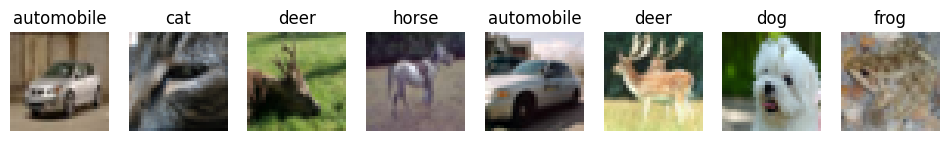

In [7]:
data = CIFAR10(batch_size=64)

batch = next(iter(data.train_dataloader()))
data.visualize(batch)

In [8]:
print(" Training size: ", len(data.train_set),"\n Validation size: ", len(data.valid_set),"\n Test size: ", len(data.test_set))

print("\n Verifying images and labels shape...", "train set")
train_loader = data.train_dataloader()
images, labels = next(iter(train_loader))
print(images.shape)   # torch.Size([batch_size=64, rgb_channels=3, height=32, width=32])
print(labels.shape)   # torch.Size([batch_size=64])
#time taken for iterating over training data
tic = time.time()
for x,y in data.train_dataloader():
    continue
print(f'iteration over training data took: {time.time()-tic:.2f} sec')

#checking labels
X, y = next(iter(data.train_dataloader()))
print(y[:5])
print(data.text_labels(y[:5]))

print("\n Verifying images and labels shape...", "validation set",)
valid_loader = data.val_dataloader()
images, labels = next(iter(valid_loader))
print(images.shape)
print(labels.shape)

print("\n Verifying images and labels shape...", "test set")
test_loader = data.test_dataloader()
images, labels = next(iter(test_loader))
print(images.shape)
print(labels.shape)


 Training size:  40000 
 Validation size:  10000 
 Test size:  10000

 Verifying images and labels shape... train set
torch.Size([64, 3, 32, 32])
torch.Size([64])
iteration over training data took: 1.78 sec
tensor([2, 4, 0, 2, 0])
['bird', 'deer', 'airplane', 'bird', 'airplane']

 Verifying images and labels shape... validation set
torch.Size([64, 3, 32, 32])
torch.Size([64])

 Verifying images and labels shape... test set
torch.Size([64, 3, 32, 32])
torch.Size([64])


## 2.4 Classifier Class

In [9]:
class Classifier(d2l.Module):
    """ base class of classificantion models in this project"""
    
    def validation_step(self, batch):
        X, y = batch
        X, y = X.to(device), y.to(device)
        Y_hat = self(X)
        self.plot('loss', self.loss(Y_hat, y), train=False)
        self.plot('accuracy', self.accuracy(Y_hat, y), train=False)

    def training_step(self, batch):
        X, y = batch
        X, y = X.to(device), y.to(device)
        Y_hat = self(X)
        loss = self.loss(Y_hat, y)
        self.plot('loss', loss, train=True)
        self.plot('accuracy', self.accuracy(Y_hat, y), train=True)
        return loss

    def accuracy(self, Y_hat, Y):
        preds = Y_hat.argmax(dim=1)
        return (preds == Y).float().mean()

#adding optimizer config function
# @d2l.add_to_class(d2l.Module)
    def configure_optimizers(self):
        return torch.optim.SGD(self.parameters(), lr=self.lr)

## 3.1 Softmax Regression

In [10]:
class SoftmaxRegressionScratch(Classifier):
    def __init__(self, num_inputs, num_outputs, lr):
        super().__init__()
        self.save_hyperparameters()
        self.W = torch.nn.Parameter(torch.randn(num_inputs, num_outputs) * 0.01)
        self.b = torch.nn.Parameter(torch.zeros(num_outputs))

    def forward(self, X):
        X = X.reshape((-1, self.W.shape[0]))
        return X @ self.W + self.b

    def loss(self, y_hat, y):
        return F.cross_entropy(y_hat, y)

## 3.2 TRAINING Softmax

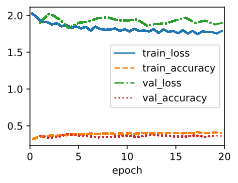

In [11]:
model = SoftmaxRegressionScratch(3072, 10, lr=0.01).to(device)
trainer = d2l.Trainer(max_epochs=20)
trainer.fit(model, data)

# one-batch test -> ok
# X_batch, y_batch = next(iter(data.train_dataloader()))
# model = SoftmaxRegressionScratch(num_inputs=3072, num_outputs=10, lr=0.01)

# for step in range(200):
#     logits = model(X_batch)
#     loss = model.loss(logits, y_batch)
#     loss.backward()

#     with torch.no_grad():
#         for param in model.parameters():
#             param -= model.lr * param.grad
#             param.grad.zero_()

#     if step % 20 == 0:
#         acc = model.accuracy(model(X_batch), y_batch).item()
#         print(step, loss.item(), acc)

In [12]:
def evaluate_accuracy(model, dataloader):
    model.eval()
    total, correct = 0, 0

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            preds = model(X).argmax(dim=1)
            total += len(y)
            correct += (preds == y).sum().item()

    return correct / total
train_acc = evaluate_accuracy(model, data.train_dataloader())
test_acc = evaluate_accuracy(model, data.test_dataloader())

train_error = (1 - train_acc)*100
test_error = (1 - test_acc)*100

print(f"Train Error: {train_error:.2f}%")
print(f"Test Error: {test_error:.2f}%")

Train Error: 57.48%
Test Error: 63.89%


## 4.1 CNN Class

In [13]:
class CNNDepthModel(Classifier):
    def __init__(self, depth, lr, dropout=0.0, weight_decay=0.0):
        super().__init__()
        self.save_hyperparameters()

        layers = []
        in_channels = 3
        out_channels = 32
        pool_count = 0

        for i in range(depth):
            # add one convolution layer
            layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False))
            # batch normalization helps deeper CNNs train more stable
            layers.append(nn.BatchNorm2d(out_channels))
            # add ReLU activation function
            layers.append(nn.ReLU(inplace=True))

            # add max pooling only to 4 so the 32 layer CNN works
            if (i + 1) % 4 == 0 and pool_count < 4:
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
                pool_count += 1

            in_channels = out_channels

        self.net = nn.Sequential(*layers)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(dropout) if dropout > 0 else None
        self.fc = nn.Linear(out_channels, 10)
        self.weight_decay = weight_decay

        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.01)
            nn.init.zeros_(m.bias)

    # this defines how the input moves through the network
    def forward(self, X):
        X = self.net(X)
        X = self.global_pool(X)
        X = torch.flatten(X, 1)

        if self.dropout is not None:
            X = self.dropout(X)

        return self.fc(X)

    # computes cross entropy loss for classification
    def loss(self, y_hat, y):
        return F.cross_entropy(y_hat, y)

    # creates the optimizer used for training
    def configure_optimizers(self):
        return torch.optim.SGD(
            self.parameters(),
            lr=self.lr,
            momentum=0.9,
            weight_decay=self.weight_decay
        )


## 4.2 CNN Model Training

In [14]:
# Model Depth 2
cnn_depth_2 = CNNDepthModel(2, lr=0.01)
history_2 = train_model_with_history(cnn_depth_2, data, num_epochs=20)

val_acc_2 = evaluate_accuracy(cnn_depth_2, data.val_dataloader())
test_acc_2 = evaluate_accuracy(cnn_depth_2, data.test_dataloader())

print(f"Depth 2 Validation Acc: {val_acc_2:.4f}")
print(f"Depth 2 Test Acc: {test_acc_2:.4f}")

Epoch 1/20 | Train Loss: 1.9619 | Val Loss: 1.7969 | Train Acc: 0.2732 | Val Acc: 0.3267
Epoch 2/20 | Train Loss: 1.7285 | Val Loss: 1.6799 | Train Acc: 0.3485 | Val Acc: 0.3747
Epoch 3/20 | Train Loss: 1.6519 | Val Loss: 1.6088 | Train Acc: 0.3809 | Val Acc: 0.4036
Epoch 4/20 | Train Loss: 1.5847 | Val Loss: 1.5714 | Train Acc: 0.4205 | Val Acc: 0.4225
Epoch 5/20 | Train Loss: 1.5233 | Val Loss: 1.4710 | Train Acc: 0.4462 | Val Acc: 0.4773
Epoch 6/20 | Train Loss: 1.4715 | Val Loss: 1.4159 | Train Acc: 0.4750 | Val Acc: 0.5058
Epoch 7/20 | Train Loss: 1.4246 | Val Loss: 1.4564 | Train Acc: 0.4910 | Val Acc: 0.4815
Epoch 8/20 | Train Loss: 1.3993 | Val Loss: 1.3673 | Train Acc: 0.5022 | Val Acc: 0.5147
Epoch 9/20 | Train Loss: 1.3728 | Val Loss: 1.3840 | Train Acc: 0.5119 | Val Acc: 0.5041
Epoch 10/20 | Train Loss: 1.3521 | Val Loss: 1.3450 | Train Acc: 0.5193 | Val Acc: 0.5136
Epoch 11/20 | Train Loss: 1.3305 | Val Loss: 1.3232 | Train Acc: 0.5274 | Val Acc: 0.5269
Epoch 12/20 | Train

In [15]:
#depth 8 model
cnn_depth_8 = CNNDepthModel(8, lr=0.01)
history_8 = train_model_with_history(cnn_depth_8, data, num_epochs=20)

val_acc_8 = evaluate_accuracy(cnn_depth_8, data.val_dataloader())
test_acc_8 = evaluate_accuracy(cnn_depth_8, data.test_dataloader())

print(f"Depth 8 Validation Acc: {val_acc_8:.4f}")
print(f"Depth 8 Test Acc: {test_acc_8:.4f}")

Epoch 1/20 | Train Loss: 1.6437 | Val Loss: 1.3795 | Train Acc: 0.3765 | Val Acc: 0.4795
Epoch 2/20 | Train Loss: 1.2004 | Val Loss: 1.5596 | Train Acc: 0.5589 | Val Acc: 0.4698
Epoch 3/20 | Train Loss: 1.0175 | Val Loss: 1.3893 | Train Acc: 0.6301 | Val Acc: 0.5259
Epoch 4/20 | Train Loss: 0.9137 | Val Loss: 1.0925 | Train Acc: 0.6735 | Val Acc: 0.6225
Epoch 5/20 | Train Loss: 0.8307 | Val Loss: 1.0101 | Train Acc: 0.7030 | Val Acc: 0.6425
Epoch 6/20 | Train Loss: 0.7634 | Val Loss: 0.9967 | Train Acc: 0.7285 | Val Acc: 0.6683
Epoch 7/20 | Train Loss: 0.7178 | Val Loss: 0.8402 | Train Acc: 0.7462 | Val Acc: 0.7127
Epoch 8/20 | Train Loss: 0.6637 | Val Loss: 0.8273 | Train Acc: 0.7650 | Val Acc: 0.7187
Epoch 9/20 | Train Loss: 0.6327 | Val Loss: 1.0160 | Train Acc: 0.7772 | Val Acc: 0.6626
Epoch 10/20 | Train Loss: 0.5997 | Val Loss: 0.8024 | Train Acc: 0.7885 | Val Acc: 0.7290
Epoch 11/20 | Train Loss: 0.5638 | Val Loss: 0.9177 | Train Acc: 0.8028 | Val Acc: 0.6958
Epoch 12/20 | Train

In [16]:
#depth 16 layers model
cnn_depth_16 = CNNDepthModel(16, lr=0.01)
history_16 = train_model_with_history(cnn_depth_16, data, num_epochs=20)

val_acc_16 = evaluate_accuracy(cnn_depth_16, data.val_dataloader())
test_acc_16 = evaluate_accuracy(cnn_depth_16, data.test_dataloader())

print(f"Depth 16 Validation Acc: {val_acc_16:.4f}")
print(f"Depth 16 Test Acc: {test_acc_16:.4f}")

Epoch 1/20 | Train Loss: 1.7115 | Val Loss: 1.4790 | Train Acc: 0.3412 | Val Acc: 0.4618
Epoch 2/20 | Train Loss: 1.1958 | Val Loss: 1.0936 | Train Acc: 0.5628 | Val Acc: 0.6054
Epoch 3/20 | Train Loss: 0.9924 | Val Loss: 1.0644 | Train Acc: 0.6431 | Val Acc: 0.6257
Epoch 4/20 | Train Loss: 0.8584 | Val Loss: 0.8762 | Train Acc: 0.6932 | Val Acc: 0.6901
Epoch 5/20 | Train Loss: 0.7625 | Val Loss: 0.8406 | Train Acc: 0.7294 | Val Acc: 0.7050
Epoch 6/20 | Train Loss: 0.6844 | Val Loss: 0.7803 | Train Acc: 0.7579 | Val Acc: 0.7304
Epoch 7/20 | Train Loss: 0.6218 | Val Loss: 0.7646 | Train Acc: 0.7805 | Val Acc: 0.7405
Epoch 8/20 | Train Loss: 0.5720 | Val Loss: 0.8425 | Train Acc: 0.7994 | Val Acc: 0.7188
Epoch 9/20 | Train Loss: 0.5235 | Val Loss: 0.8227 | Train Acc: 0.8175 | Val Acc: 0.7314
Epoch 10/20 | Train Loss: 0.4868 | Val Loss: 0.6936 | Train Acc: 0.8297 | Val Acc: 0.7654
Epoch 11/20 | Train Loss: 0.4499 | Val Loss: 0.7606 | Train Acc: 0.8422 | Val Acc: 0.7528
Epoch 12/20 | Train

In [17]:
#depth 32 layers model
cnn_depth_32 = CNNDepthModel(32, lr=0.01)
history_32 = train_model_with_history(cnn_depth_32, data, num_epochs=20)

val_acc_32 = evaluate_accuracy(cnn_depth_32, data.val_dataloader())
test_acc_32 = evaluate_accuracy(cnn_depth_32, data.test_dataloader())

print(f"Depth 32 Validation Acc: {val_acc_32:.4f}")
print(f"Depth 32 Test Acc: {test_acc_32:.4f}")

Epoch 1/20 | Train Loss: 1.9447 | Val Loss: 1.7150 | Train Acc: 0.2497 | Val Acc: 0.3324
Epoch 2/20 | Train Loss: 1.5639 | Val Loss: 1.4798 | Train Acc: 0.4072 | Val Acc: 0.4552
Epoch 3/20 | Train Loss: 1.3324 | Val Loss: 1.3335 | Train Acc: 0.5148 | Val Acc: 0.5233
Epoch 4/20 | Train Loss: 1.1366 | Val Loss: 1.1046 | Train Acc: 0.5966 | Val Acc: 0.6087
Epoch 5/20 | Train Loss: 1.0093 | Val Loss: 1.1034 | Train Acc: 0.6425 | Val Acc: 0.6046
Epoch 6/20 | Train Loss: 0.9049 | Val Loss: 0.9250 | Train Acc: 0.6777 | Val Acc: 0.6745
Epoch 7/20 | Train Loss: 0.8338 | Val Loss: 0.9228 | Train Acc: 0.7088 | Val Acc: 0.6749
Epoch 8/20 | Train Loss: 0.7717 | Val Loss: 0.9900 | Train Acc: 0.7330 | Val Acc: 0.6714
Epoch 9/20 | Train Loss: 0.7123 | Val Loss: 0.9033 | Train Acc: 0.7527 | Val Acc: 0.7022
Epoch 10/20 | Train Loss: 0.6564 | Val Loss: 0.8945 | Train Acc: 0.7742 | Val Acc: 0.7043
Epoch 11/20 | Train Loss: 0.6295 | Val Loss: 0.7607 | Train Acc: 0.7825 | Val Acc: 0.7449
Epoch 12/20 | Train

In [18]:
#Compare all model results at once using pandas
results_df = pd.DataFrame([
    {"Depth": 2, "Validation Accuracy": val_acc_2, "Test Accuracy": test_acc_2},
    {"Depth": 8, "Validation Accuracy": val_acc_8, "Test Accuracy": test_acc_8},
    {"Depth": 16, "Validation Accuracy": val_acc_16, "Test Accuracy": test_acc_16},
    {"Depth": 32, "Validation Accuracy": val_acc_32, "Test Accuracy": test_acc_32},
])

results_df

,Depth,Validation Accuracy,Test Accuracy
0,2,0.5716,0.5761
1,8,0.7672,0.7727
2,16,0.7707,0.7773
3,32,0.7475,0.7539


### plotting

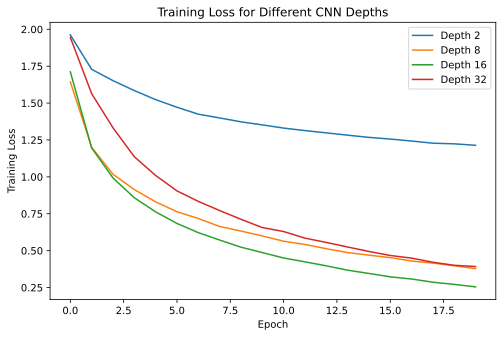

In [19]:
#training loss compare
plt.figure(figsize=(8, 5))
plt.plot(history_2["train_losses"], label="Depth 2")
plt.plot(history_8["train_losses"], label="Depth 8")
plt.plot(history_16["train_losses"], label="Depth 16")
plt.plot(history_32["train_losses"], label="Depth 32")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss for Different CNN Depths")
plt.legend()
plt.show()

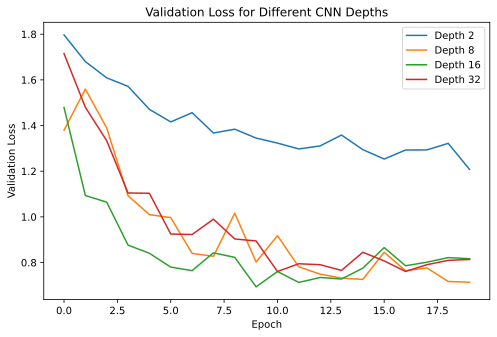

In [20]:
#validation loss compare
plt.figure(figsize=(8, 5))
plt.plot(history_2["val_losses"], label="Depth 2")
plt.plot(history_8["val_losses"], label="Depth 8")
plt.plot(history_16["val_losses"], label="Depth 16")
plt.plot(history_32["val_losses"], label="Depth 32")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss for Different CNN Depths")
plt.legend()
plt.show()

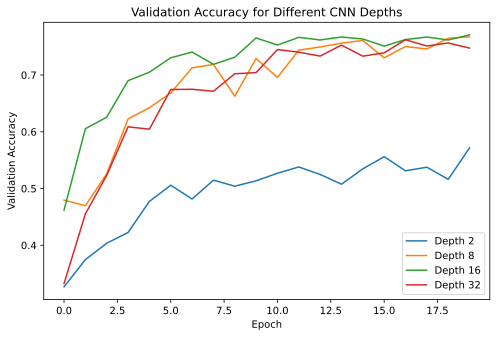

In [21]:
#validation accuracy compare
plt.figure(figsize=(8, 5))
plt.plot(history_2["val_accs"], label="Depth 2")
plt.plot(history_8["val_accs"], label="Depth 8")
plt.plot(history_16["val_accs"], label="Depth 16")
plt.plot(history_32["val_accs"], label="Depth 32")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy for Different CNN Depths")
plt.legend()
plt.show()

## 4.3 CNN Part B Choosing Deep base model with drop out and weight decay

In [22]:
# This code block reuses the depth 16 model
deep_base_model = cnn_depth_16
deep_base_history = history_16
deep_base_val_acc = val_acc_16
deep_base_test_acc = test_acc_16

print(f"Baseline Validation Acc: {deep_base_val_acc:.4f}")
print(f"Baseline Test Acc: {deep_base_test_acc:.4f}")


Baseline Validation Acc: 0.7707
Baseline Test Acc: 0.7773


In [23]:
#Training 16 layers CNN model with dropout
deep_dropout_model = CNNDepthModel(depth=16, lr=0.01, dropout=0.5)
deep_dropout_history = train_model_with_history(deep_dropout_model, data, num_epochs=20)

deep_dropout_val_acc = evaluate_accuracy(deep_dropout_model, data.val_dataloader())
deep_dropout_test_acc = evaluate_accuracy(deep_dropout_model, data.test_dataloader())

print(f"Dropout Validation Acc: {deep_dropout_val_acc:.4f}")
print(f"Dropout Test Acc: {deep_dropout_test_acc:.4f}")

Epoch 1/20 | Train Loss: 1.8140 | Val Loss: 1.4795 | Train Acc: 0.2884 | Val Acc: 0.4209
Epoch 2/20 | Train Loss: 1.4494 | Val Loss: 1.2373 | Train Acc: 0.4653 | Val Acc: 0.5434
Epoch 3/20 | Train Loss: 1.2372 | Val Loss: 1.1264 | Train Acc: 0.5632 | Val Acc: 0.6058
Epoch 4/20 | Train Loss: 1.0967 | Val Loss: 1.0844 | Train Acc: 0.6159 | Val Acc: 0.6060
Epoch 5/20 | Train Loss: 1.0084 | Val Loss: 0.9248 | Train Acc: 0.6532 | Val Acc: 0.6708
Epoch 6/20 | Train Loss: 0.9359 | Val Loss: 0.8585 | Train Acc: 0.6813 | Val Acc: 0.6949
Epoch 7/20 | Train Loss: 0.8619 | Val Loss: 0.7838 | Train Acc: 0.7071 | Val Acc: 0.7252
Epoch 8/20 | Train Loss: 0.8181 | Val Loss: 0.8344 | Train Acc: 0.7251 | Val Acc: 0.7129
Epoch 9/20 | Train Loss: 0.7810 | Val Loss: 0.8121 | Train Acc: 0.7364 | Val Acc: 0.7249
Epoch 10/20 | Train Loss: 0.7290 | Val Loss: 0.8467 | Train Acc: 0.7570 | Val Acc: 0.7247
Epoch 11/20 | Train Loss: 0.7060 | Val Loss: 0.7431 | Train Acc: 0.7649 | Val Acc: 0.7546
Epoch 12/20 | Train

In [24]:
# 16 layers with weight decay
deep_weight_decay_model = CNNDepthModel(depth=16, lr=0.01, weight_decay=1e-4)
deep_weight_decay_history = train_model_with_history(deep_weight_decay_model, data, num_epochs=20)

deep_weight_decay_val_acc = evaluate_accuracy(deep_weight_decay_model, data.val_dataloader())
deep_weight_decay_test_acc = evaluate_accuracy(deep_weight_decay_model, data.test_dataloader())

print(f"Weight Decay Validation Acc: {deep_weight_decay_val_acc:.4f}")
print(f"Weight Decay Test Acc: {deep_weight_decay_test_acc:.4f}")

Epoch 1/20 | Train Loss: 1.6996 | Val Loss: 1.3969 | Train Acc: 0.3491 | Val Acc: 0.4941
Epoch 2/20 | Train Loss: 1.2179 | Val Loss: 1.0558 | Train Acc: 0.5565 | Val Acc: 0.6111
Epoch 3/20 | Train Loss: 0.9873 | Val Loss: 1.0696 | Train Acc: 0.6448 | Val Acc: 0.6206
Epoch 4/20 | Train Loss: 0.8553 | Val Loss: 0.9446 | Train Acc: 0.6955 | Val Acc: 0.6677
Epoch 5/20 | Train Loss: 0.7573 | Val Loss: 0.8708 | Train Acc: 0.7305 | Val Acc: 0.6942
Epoch 6/20 | Train Loss: 0.6819 | Val Loss: 0.8785 | Train Acc: 0.7594 | Val Acc: 0.7018
Epoch 7/20 | Train Loss: 0.6251 | Val Loss: 0.7396 | Train Acc: 0.7799 | Val Acc: 0.7422
Epoch 8/20 | Train Loss: 0.5713 | Val Loss: 0.7476 | Train Acc: 0.8008 | Val Acc: 0.7445
Epoch 9/20 | Train Loss: 0.5340 | Val Loss: 0.7574 | Train Acc: 0.8141 | Val Acc: 0.7483
Epoch 10/20 | Train Loss: 0.4945 | Val Loss: 0.7374 | Train Acc: 0.8259 | Val Acc: 0.7569
Epoch 11/20 | Train Loss: 0.4617 | Val Loss: 0.7353 | Train Acc: 0.8387 | Val Acc: 0.7606
Epoch 12/20 | Train

In [25]:
# with both drop out and weight decay
deep_both_model = CNNDepthModel(depth=16, lr=0.01, dropout=0.5, weight_decay=1e-4)
deep_both_history = train_model_with_history(deep_both_model, data, num_epochs=20)

deep_both_val_acc = evaluate_accuracy(deep_both_model, data.val_dataloader())
deep_both_test_acc = evaluate_accuracy(deep_both_model, data.test_dataloader())

print(f"Dropout + Weight Decay Validation Acc: {deep_both_val_acc:.4f}")
print(f"Dropout + Weight Decay Test Acc: {deep_both_test_acc:.4f}")

Epoch 1/20 | Train Loss: 1.8456 | Val Loss: 1.5756 | Train Acc: 0.2690 | Val Acc: 0.3942
Epoch 2/20 | Train Loss: 1.4872 | Val Loss: 1.4457 | Train Acc: 0.4385 | Val Acc: 0.4817
Epoch 3/20 | Train Loss: 1.2646 | Val Loss: 1.1275 | Train Acc: 0.5502 | Val Acc: 0.5936
Epoch 4/20 | Train Loss: 1.1123 | Val Loss: 0.9916 | Train Acc: 0.6122 | Val Acc: 0.6503
Epoch 5/20 | Train Loss: 1.0131 | Val Loss: 0.9809 | Train Acc: 0.6501 | Val Acc: 0.6535
Epoch 6/20 | Train Loss: 0.9341 | Val Loss: 0.8853 | Train Acc: 0.6827 | Val Acc: 0.6930
Epoch 7/20 | Train Loss: 0.8786 | Val Loss: 0.9002 | Train Acc: 0.7059 | Val Acc: 0.6893
Epoch 8/20 | Train Loss: 0.8206 | Val Loss: 0.8246 | Train Acc: 0.7239 | Val Acc: 0.7175
Epoch 9/20 | Train Loss: 0.7752 | Val Loss: 0.7608 | Train Acc: 0.7440 | Val Acc: 0.7433
Epoch 10/20 | Train Loss: 0.7443 | Val Loss: 0.7473 | Train Acc: 0.7548 | Val Acc: 0.7511
Epoch 11/20 | Train Loss: 0.7093 | Val Loss: 0.9312 | Train Acc: 0.7651 | Val Acc: 0.7024
Epoch 12/20 | Train

In [26]:
#Comparison
improved_results_df = pd.DataFrame([
    {
        "Model": "Baseline",
        "Validation Accuracy": deep_base_val_acc,
        "Test Accuracy": deep_base_test_acc
    },
    {
        "Model": "Dropout",
        "Validation Accuracy": deep_dropout_val_acc,
        "Test Accuracy": deep_dropout_test_acc
    },
    {
        "Model": "Weight Decay",
        "Validation Accuracy": deep_weight_decay_val_acc,
        "Test Accuracy": deep_weight_decay_test_acc
    },
    {
        "Model": "Dropout + Weight Decay",
        "Validation Accuracy": deep_both_val_acc,
        "Test Accuracy": deep_both_test_acc
    }
])

improved_results_df

,Model,Validation Accuracy,Test Accuracy
0,Baseline,0.7707,0.7773
1,Dropout,0.7396,0.7372
2,Weight Decay,0.7683,0.7691
3,Dropout + Weight Decay,0.7710,0.7646


### Plotting

Validation Accuracy

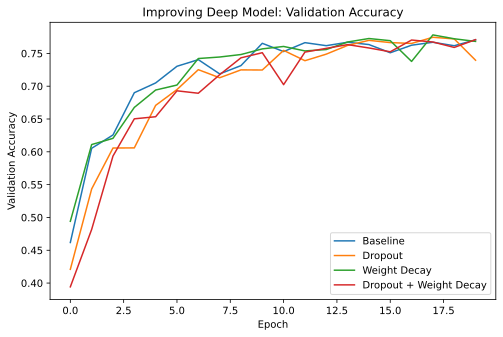

In [27]:
plt.figure(figsize=(8, 5))
plt.plot(deep_base_history["val_accs"], label="Baseline")
plt.plot(deep_dropout_history["val_accs"], label="Dropout")
plt.plot(deep_weight_decay_history["val_accs"], label="Weight Decay")
plt.plot(deep_both_history["val_accs"], label="Dropout + Weight Decay")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Improving Deep Model: Validation Accuracy")
plt.legend()
plt.show()

Validation loss

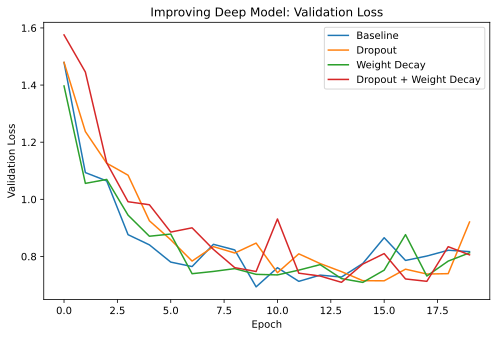

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(deep_base_history["val_losses"], label="Baseline")
plt.plot(deep_dropout_history["val_losses"], label="Dropout")
plt.plot(deep_weight_decay_history["val_losses"], label="Weight Decay")
plt.plot(deep_both_history["val_losses"], label="Dropout + Weight Decay")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Improving Deep Model: Validation Loss")
plt.legend()
plt.show()

## 4.4 Model learning rate variations

In [29]:
lr_model_000001 = CNNDepthModel(depth=16, lr=0.000001)
lr_history_000001 = train_model_with_history(lr_model_000001, data, num_epochs=20)

val_acc_000001 = evaluate_accuracy(lr_model_000001, data.val_dataloader())
test_acc_000001 = evaluate_accuracy(lr_model_000001, data.test_dataloader())

print(f"LR 0.000001 Validation Acc: {val_acc_000001:.4f}")
print(f"LR 0.000001 Test Acc: {test_acc_000001:.4f}")

Epoch 1/20 | Train Loss: 2.3027 | Val Loss: 2.3033 | Train Acc: 0.1042 | Val Acc: 0.1010
Epoch 2/20 | Train Loss: 2.3025 | Val Loss: 2.3032 | Train Acc: 0.1052 | Val Acc: 0.1038
Epoch 3/20 | Train Loss: 2.3025 | Val Loss: 2.3031 | Train Acc: 0.1041 | Val Acc: 0.1015
Epoch 4/20 | Train Loss: 2.3023 | Val Loss: 2.3029 | Train Acc: 0.1055 | Val Acc: 0.1044
Epoch 5/20 | Train Loss: 2.3022 | Val Loss: 2.3029 | Train Acc: 0.1069 | Val Acc: 0.1069
Epoch 6/20 | Train Loss: 2.3022 | Val Loss: 2.3026 | Train Acc: 0.1058 | Val Acc: 0.1013
Epoch 7/20 | Train Loss: 2.3021 | Val Loss: 2.3024 | Train Acc: 0.1063 | Val Acc: 0.1056
Epoch 8/20 | Train Loss: 2.3018 | Val Loss: 2.3025 | Train Acc: 0.1080 | Val Acc: 0.1060
Epoch 9/20 | Train Loss: 2.3017 | Val Loss: 2.3023 | Train Acc: 0.1083 | Val Acc: 0.1072
Epoch 10/20 | Train Loss: 2.3016 | Val Loss: 2.3022 | Train Acc: 0.1076 | Val Acc: 0.1063
Epoch 11/20 | Train Loss: 2.3015 | Val Loss: 2.3021 | Train Acc: 0.1098 | Val Acc: 0.1083
Epoch 12/20 | Train

In [30]:
lr_model_0001 = CNNDepthModel(depth=16, lr=0.0001)
lr_history_0001 = train_model_with_history(lr_model_0001, data, num_epochs=20)

val_acc_0001 = evaluate_accuracy(lr_model_0001, data.val_dataloader())
test_acc_0001 = evaluate_accuracy(lr_model_0001, data.test_dataloader())

print(f"LR 0.0001 Validation Acc: {val_acc_0001:.4f}")
print(f"LR 0.0001 Test Acc: {test_acc_0001:.4f}")

Epoch 1/20 | Train Loss: 2.2984 | Val Loss: 2.2911 | Train Acc: 0.1089 | Val Acc: 0.1062
Epoch 2/20 | Train Loss: 2.2827 | Val Loss: 2.2696 | Train Acc: 0.1158 | Val Acc: 0.1418
Epoch 3/20 | Train Loss: 2.2546 | Val Loss: 2.2295 | Train Acc: 0.1610 | Val Acc: 0.1828
Epoch 4/20 | Train Loss: 2.2065 | Val Loss: 2.1762 | Train Acc: 0.1835 | Val Acc: 0.1947
Epoch 5/20 | Train Loss: 2.1477 | Val Loss: 2.1139 | Train Acc: 0.1943 | Val Acc: 0.1950
Epoch 6/20 | Train Loss: 2.0860 | Val Loss: 2.0509 | Train Acc: 0.2009 | Val Acc: 0.2080
Epoch 7/20 | Train Loss: 2.0310 | Val Loss: 1.9950 | Train Acc: 0.2113 | Val Acc: 0.2197
Epoch 8/20 | Train Loss: 1.9808 | Val Loss: 1.9481 | Train Acc: 0.2242 | Val Acc: 0.2328
Epoch 9/20 | Train Loss: 1.9396 | Val Loss: 1.9109 | Train Acc: 0.2345 | Val Acc: 0.2549
Epoch 10/20 | Train Loss: 1.9014 | Val Loss: 1.8700 | Train Acc: 0.2566 | Val Acc: 0.2731
Epoch 11/20 | Train Loss: 1.8666 | Val Loss: 1.8436 | Train Acc: 0.2706 | Val Acc: 0.2815
Epoch 12/20 | Train

In [31]:
lr_model_001 = CNNDepthModel(depth=16, lr=0.001)
lr_history_001 = train_model_with_history(lr_model_001, data, num_epochs=20)

val_acc_001 = evaluate_accuracy(lr_model_001, data.val_dataloader())
test_acc_001 = evaluate_accuracy(lr_model_001, data.test_dataloader())

print(f"LR 0.001 Validation Acc: {val_acc_001:.4f}")
print(f"LR 0.001 Test Acc: {test_acc_001:.4f}")


Epoch 1/20 | Train Loss: 2.0675 | Val Loss: 1.8335 | Train Acc: 0.2004 | Val Acc: 0.2778
Epoch 2/20 | Train Loss: 1.7466 | Val Loss: 1.6693 | Train Acc: 0.3025 | Val Acc: 0.3437
Epoch 3/20 | Train Loss: 1.6176 | Val Loss: 1.5858 | Train Acc: 0.3697 | Val Acc: 0.3951
Epoch 4/20 | Train Loss: 1.5126 | Val Loss: 1.5043 | Train Acc: 0.4178 | Val Acc: 0.4197
Epoch 5/20 | Train Loss: 1.3984 | Val Loss: 1.3506 | Train Acc: 0.4724 | Val Acc: 0.4905
Epoch 6/20 | Train Loss: 1.2751 | Val Loss: 1.2321 | Train Acc: 0.5283 | Val Acc: 0.5444
Epoch 7/20 | Train Loss: 1.1638 | Val Loss: 1.1945 | Train Acc: 0.5750 | Val Acc: 0.5669
Epoch 8/20 | Train Loss: 1.0725 | Val Loss: 1.0899 | Train Acc: 0.6086 | Val Acc: 0.6004
Epoch 9/20 | Train Loss: 1.0024 | Val Loss: 1.0359 | Train Acc: 0.6355 | Val Acc: 0.6234
Epoch 10/20 | Train Loss: 0.9463 | Val Loss: 1.0073 | Train Acc: 0.6581 | Val Acc: 0.6347
Epoch 11/20 | Train Loss: 0.8952 | Val Loss: 0.9786 | Train Acc: 0.6748 | Val Acc: 0.6439
Epoch 12/20 | Train

In [32]:
lr_model_01 = CNNDepthModel(depth=16, lr=0.01)
lr_history_01 = train_model_with_history(lr_model_01, data, num_epochs=20)

val_acc_01 = evaluate_accuracy(lr_model_01, data.val_dataloader())
test_acc_01 = evaluate_accuracy(lr_model_01, data.test_dataloader())

print(f"LR 0.01 Validation Acc: {val_acc_01:.4f}")
print(f"LR 0.01 Test Acc: {test_acc_01:.4f}")

Epoch 1/20 | Train Loss: 1.6773 | Val Loss: 1.4366 | Train Acc: 0.3603 | Val Acc: 0.4644
Epoch 2/20 | Train Loss: 1.2115 | Val Loss: 1.1810 | Train Acc: 0.5617 | Val Acc: 0.5666
Epoch 3/20 | Train Loss: 0.9842 | Val Loss: 0.9825 | Train Acc: 0.6462 | Val Acc: 0.6489
Epoch 4/20 | Train Loss: 0.8446 | Val Loss: 0.9766 | Train Acc: 0.6986 | Val Acc: 0.6584
Epoch 5/20 | Train Loss: 0.7487 | Val Loss: 0.8397 | Train Acc: 0.7333 | Val Acc: 0.7028
Epoch 6/20 | Train Loss: 0.6800 | Val Loss: 0.7708 | Train Acc: 0.7602 | Val Acc: 0.7325
Epoch 7/20 | Train Loss: 0.6244 | Val Loss: 0.7581 | Train Acc: 0.7789 | Val Acc: 0.7385
Epoch 8/20 | Train Loss: 0.5629 | Val Loss: 0.7787 | Train Acc: 0.8016 | Val Acc: 0.7364
Epoch 9/20 | Train Loss: 0.5236 | Val Loss: 0.7333 | Train Acc: 0.8152 | Val Acc: 0.7532
Epoch 10/20 | Train Loss: 0.4856 | Val Loss: 0.7918 | Train Acc: 0.8314 | Val Acc: 0.7415
Epoch 11/20 | Train Loss: 0.4476 | Val Loss: 0.7350 | Train Acc: 0.8439 | Val Acc: 0.7646
Epoch 12/20 | Train

In [33]:
lr_model_1 = CNNDepthModel(depth=16, lr=1.0)
lr_history_1 = train_model_with_history(lr_model_1, data, num_epochs=20)

val_acc_1 = evaluate_accuracy(lr_model_1, data.val_dataloader())
test_acc_1 = evaluate_accuracy(lr_model_1, data.test_dataloader())

print(f"LR 1.0 Validation Acc: {val_acc_1:.4f}")
print(f"LR 1.0 Test Acc: {test_acc_1:.4f}")

Epoch 1/20 | Train Loss: 2.3451 | Val Loss: 2.3312 | Train Acc: 0.0985 | Val Acc: 0.1001
Epoch 2/20 | Train Loss: 2.3385 | Val Loss: 2.3278 | Train Acc: 0.0974 | Val Acc: 0.1026
Epoch 3/20 | Train Loss: 2.3389 | Val Loss: 2.3300 | Train Acc: 0.0975 | Val Acc: 0.1015
Epoch 4/20 | Train Loss: 2.3401 | Val Loss: 2.3581 | Train Acc: 0.0989 | Val Acc: 0.1014
Epoch 5/20 | Train Loss: 2.3348 | Val Loss: 2.3657 | Train Acc: 0.1004 | Val Acc: 0.0972
Epoch 6/20 | Train Loss: 2.3408 | Val Loss: 2.3580 | Train Acc: 0.1015 | Val Acc: 0.1014
Epoch 7/20 | Train Loss: 2.3388 | Val Loss: 2.3238 | Train Acc: 0.1002 | Val Acc: 0.0996
Epoch 8/20 | Train Loss: 2.3410 | Val Loss: 2.3560 | Train Acc: 0.1006 | Val Acc: 0.1025
Epoch 9/20 | Train Loss: 2.3430 | Val Loss: 2.3565 | Train Acc: 0.1008 | Val Acc: 0.1025
Epoch 10/20 | Train Loss: 2.3363 | Val Loss: 2.3258 | Train Acc: 0.0984 | Val Acc: 0.0996
Epoch 11/20 | Train Loss: 2.3376 | Val Loss: 2.3290 | Train Acc: 0.1017 | Val Acc: 0.1016
Epoch 12/20 | Train

In [34]:
lr_results_df = pd.DataFrame([
    {"Learning Rate": 0.000001, "Validation Accuracy": val_acc_000001, "Test Accuracy": test_acc_000001},
    {"Learning Rate": 0.0001,   "Validation Accuracy": val_acc_0001,   "Test Accuracy": test_acc_0001},
    {"Learning Rate": 0.001,    "Validation Accuracy": val_acc_001,    "Test Accuracy": test_acc_001},
    {"Learning Rate": 0.01,     "Validation Accuracy": val_acc_01,     "Test Accuracy": test_acc_01},
    {"Learning Rate": 1.0,      "Validation Accuracy": val_acc_1,      "Test Accuracy": test_acc_1},
])

lr_results_df

,Learning Rate,Validation Accuracy,Test Accuracy
0,0.000001,0.1119,0.1126
1,0.000100,0.3741,0.3683
2,0.001000,0.6901,0.6856
3,0.010000,0.7450,0.7493
4,1.000000,0.1000,0.1001


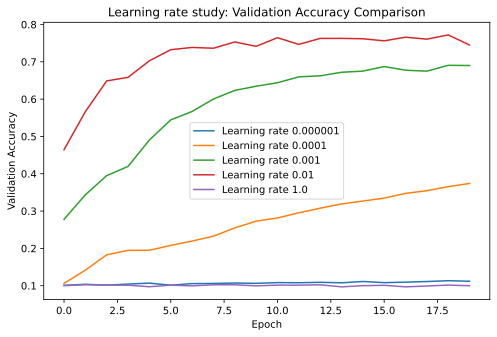

In [43]:
plt.figure(figsize=(8, 5))
plt.plot(lr_history_000001["val_accs"], label="Learning rate 0.000001")
plt.plot(lr_history_0001["val_accs"], label="Learning rate 0.0001")
plt.plot(lr_history_001["val_accs"], label="Learning rate 0.001")
plt.plot(lr_history_01["val_accs"], label="Learning rate 0.01")
plt.plot(lr_history_1["val_accs"], label="Learning rate 1.0")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Learning rate study: Validation Accuracy Comparison")
plt.legend()
plt.show()

## 4.5 Model Mini-batch variations

In [35]:
data_bs_1 = CIFAR10(batch_size=1)
batch_model_1 = CNNDepthModel(depth=16, lr=0.01)
batch_history_1 = train_model_with_history(batch_model_1, data_bs_1, num_epochs=20)

val_acc_bs_1 = evaluate_accuracy(batch_model_1, data_bs_1.val_dataloader())
test_acc_bs_1 = evaluate_accuracy(batch_model_1, data_bs_1.test_dataloader())

print(f"Batch Size 1 Validation Acc: {val_acc_bs_1:.4f}")
print(f"Batch Size 1 Test Acc: {test_acc_bs_1:.4f}")

Files already downloaded and verified
Files already downloaded and verified
Epoch 1/20 | Train Loss: 2.0806 | Val Loss: 2.0019 | Train Acc: 0.2064 | Val Acc: 0.2023
Epoch 2/20 | Train Loss: 1.7049 | Val Loss: 1.9110 | Train Acc: 0.3560 | Val Acc: 0.2572
Epoch 3/20 | Train Loss: 1.4273 | Val Loss: 2.0318 | Train Acc: 0.4843 | Val Acc: 0.2632
Epoch 4/20 | Train Loss: 1.2278 | Val Loss: 1.7213 | Train Acc: 0.5643 | Val Acc: 0.3638
Epoch 5/20 | Train Loss: 1.1026 | Val Loss: 1.9112 | Train Acc: 0.6138 | Val Acc: 0.3284
Epoch 6/20 | Train Loss: 1.0089 | Val Loss: 1.7902 | Train Acc: 0.6500 | Val Acc: 0.3470
Epoch 7/20 | Train Loss: 0.9287 | Val Loss: 1.9659 | Train Acc: 0.6773 | Val Acc: 0.2847
Epoch 8/20 | Train Loss: 0.8587 | Val Loss: 1.7562 | Train Acc: 0.7038 | Val Acc: 0.3822
Epoch 9/20 | Train Loss: 0.8071 | Val Loss: 1.7440 | Train Acc: 0.7232 | Val Acc: 0.3658
Epoch 10/20 | Train Loss: 0.7610 | Val Loss: 1.8281 | Train Acc: 0.7396 | Val Acc: 0.3406
Epoch 11/20 | Train Loss: 0.7161 

In [36]:
data_bs_8 = CIFAR10(batch_size=8)
batch_model_8 = CNNDepthModel(depth=16, lr=0.01)
batch_history_8 = train_model_with_history(batch_model_8, data_bs_8, num_epochs=20)

val_acc_bs_8 = evaluate_accuracy(batch_model_8, data_bs_8.val_dataloader())
test_acc_bs_8 = evaluate_accuracy(batch_model_8, data_bs_8.test_dataloader())

print(f"Batch Size 8 Validation Acc: {val_acc_bs_8:.4f}")
print(f"Batch Size 8 Test Acc: {test_acc_bs_8:.4f}")

Files already downloaded and verified
Files already downloaded and verified
Epoch 1/20 | Train Loss: 1.6770 | Val Loss: 1.2767 | Train Acc: 0.3772 | Val Acc: 0.5344
Epoch 2/20 | Train Loss: 1.2353 | Val Loss: 1.1132 | Train Acc: 0.5619 | Val Acc: 0.5978
Epoch 3/20 | Train Loss: 1.0080 | Val Loss: 0.8827 | Train Acc: 0.6444 | Val Acc: 0.6909
Epoch 4/20 | Train Loss: 0.8779 | Val Loss: 0.8571 | Train Acc: 0.6931 | Val Acc: 0.7124
Epoch 5/20 | Train Loss: 0.7904 | Val Loss: 0.8022 | Train Acc: 0.7281 | Val Acc: 0.7203
Epoch 6/20 | Train Loss: 0.7238 | Val Loss: 0.7497 | Train Acc: 0.7492 | Val Acc: 0.7460
Epoch 7/20 | Train Loss: 0.6700 | Val Loss: 0.7249 | Train Acc: 0.7686 | Val Acc: 0.7555
Epoch 8/20 | Train Loss: 0.6306 | Val Loss: 0.7196 | Train Acc: 0.7826 | Val Acc: 0.7562
Epoch 9/20 | Train Loss: 0.5885 | Val Loss: 0.7549 | Train Acc: 0.7953 | Val Acc: 0.7467
Epoch 10/20 | Train Loss: 0.5542 | Val Loss: 0.6883 | Train Acc: 0.8079 | Val Acc: 0.7744
Epoch 11/20 | Train Loss: 0.5242 

In [37]:
data_bs_16 = CIFAR10(batch_size=16)
batch_model_16 = CNNDepthModel(depth=16, lr=0.01)
batch_history_16 = train_model_with_history(batch_model_16, data_bs_16, num_epochs=20)

val_acc_bs_16 = evaluate_accuracy(batch_model_16, data_bs_16.val_dataloader())
test_acc_bs_16 = evaluate_accuracy(batch_model_16, data_bs_16.test_dataloader())

print(f"Batch Size 16 Validation Acc: {val_acc_bs_16:.4f}")
print(f"Batch Size 16 Test Acc: {test_acc_bs_16:.4f}")

Files already downloaded and verified
Files already downloaded and verified
Epoch 1/20 | Train Loss: 1.6166 | Val Loss: 1.3969 | Train Acc: 0.3962 | Val Acc: 0.5073
Epoch 2/20 | Train Loss: 1.1696 | Val Loss: 0.9635 | Train Acc: 0.5852 | Val Acc: 0.6598
Epoch 3/20 | Train Loss: 0.9632 | Val Loss: 0.8666 | Train Acc: 0.6631 | Val Acc: 0.6992
Epoch 4/20 | Train Loss: 0.8378 | Val Loss: 0.8579 | Train Acc: 0.7090 | Val Acc: 0.6992
Epoch 5/20 | Train Loss: 0.7443 | Val Loss: 0.7745 | Train Acc: 0.7416 | Val Acc: 0.7380
Epoch 6/20 | Train Loss: 0.6859 | Val Loss: 0.7247 | Train Acc: 0.7656 | Val Acc: 0.7534
Epoch 7/20 | Train Loss: 0.6281 | Val Loss: 0.6838 | Train Acc: 0.7832 | Val Acc: 0.7640
Epoch 8/20 | Train Loss: 0.5838 | Val Loss: 0.6857 | Train Acc: 0.7980 | Val Acc: 0.7703
Epoch 9/20 | Train Loss: 0.5442 | Val Loss: 0.6663 | Train Acc: 0.8113 | Val Acc: 0.7756
Epoch 10/20 | Train Loss: 0.5125 | Val Loss: 0.6479 | Train Acc: 0.8218 | Val Acc: 0.7876
Epoch 11/20 | Train Loss: 0.4802 

In [38]:
data_bs_64 = CIFAR10(batch_size=64)
batch_model_64 = CNNDepthModel(depth=16, lr=0.01)
batch_history_64 = train_model_with_history(batch_model_64, data_bs_64, num_epochs=20)

val_acc_bs_64 = evaluate_accuracy(batch_model_64, data_bs_64.val_dataloader())
test_acc_bs_64 = evaluate_accuracy(batch_model_64, data_bs_64.test_dataloader())

print(f"Batch Size 64 Validation Acc: {val_acc_bs_64:.4f}")
print(f"Batch Size 64 Test Acc: {test_acc_bs_64:.4f}")

Files already downloaded and verified
Files already downloaded and verified
Epoch 1/20 | Train Loss: 1.7028 | Val Loss: 1.5470 | Train Acc: 0.3456 | Val Acc: 0.4359
Epoch 2/20 | Train Loss: 1.1926 | Val Loss: 1.0688 | Train Acc: 0.5656 | Val Acc: 0.6123
Epoch 3/20 | Train Loss: 0.9803 | Val Loss: 1.0075 | Train Acc: 0.6451 | Val Acc: 0.6442
Epoch 4/20 | Train Loss: 0.8427 | Val Loss: 1.1025 | Train Acc: 0.6975 | Val Acc: 0.6237
Epoch 5/20 | Train Loss: 0.7457 | Val Loss: 0.8732 | Train Acc: 0.7352 | Val Acc: 0.7012
Epoch 6/20 | Train Loss: 0.6709 | Val Loss: 0.7764 | Train Acc: 0.7639 | Val Acc: 0.7332
Epoch 7/20 | Train Loss: 0.6137 | Val Loss: 0.8222 | Train Acc: 0.7838 | Val Acc: 0.7246
Epoch 8/20 | Train Loss: 0.5651 | Val Loss: 0.8454 | Train Acc: 0.8012 | Val Acc: 0.7239
Epoch 9/20 | Train Loss: 0.5186 | Val Loss: 0.8624 | Train Acc: 0.8185 | Val Acc: 0.7204
Epoch 10/20 | Train Loss: 0.4824 | Val Loss: 0.8108 | Train Acc: 0.8309 | Val Acc: 0.7328
Epoch 11/20 | Train Loss: 0.4511 

In [39]:
data_bs_256 = CIFAR10(batch_size=256)
batch_model_256 = CNNDepthModel(depth=16, lr=0.01)
batch_history_256 = train_model_with_history(batch_model_256, data_bs_256, num_epochs=20)

val_acc_bs_256 = evaluate_accuracy(batch_model_256, data_bs_256.val_dataloader())
test_acc_bs_256 = evaluate_accuracy(batch_model_256, data_bs_256.test_dataloader())

print(f"Batch Size 256 Validation Acc: {val_acc_bs_256:.4f}")
print(f"Batch Size 256 Test Acc: {test_acc_bs_256:.4f}")

Files already downloaded and verified
Files already downloaded and verified
Epoch 1/20 | Train Loss: 1.9869 | Val Loss: 1.6960 | Train Acc: 0.2287 | Val Acc: 0.3326
Epoch 2/20 | Train Loss: 1.5366 | Val Loss: 1.4691 | Train Acc: 0.4081 | Val Acc: 0.4374
Epoch 3/20 | Train Loss: 1.3020 | Val Loss: 1.3204 | Train Acc: 0.5155 | Val Acc: 0.5220
Epoch 4/20 | Train Loss: 1.1210 | Val Loss: 1.1233 | Train Acc: 0.5905 | Val Acc: 0.5927
Epoch 5/20 | Train Loss: 0.9985 | Val Loss: 1.0705 | Train Acc: 0.6364 | Val Acc: 0.6174
Epoch 6/20 | Train Loss: 0.9078 | Val Loss: 1.0141 | Train Acc: 0.6686 | Val Acc: 0.6405
Epoch 7/20 | Train Loss: 0.8304 | Val Loss: 1.0270 | Train Acc: 0.7032 | Val Acc: 0.6455
Epoch 8/20 | Train Loss: 0.7703 | Val Loss: 1.0269 | Train Acc: 0.7236 | Val Acc: 0.6471
Epoch 9/20 | Train Loss: 0.7202 | Val Loss: 0.8810 | Train Acc: 0.7403 | Val Acc: 0.6907
Epoch 10/20 | Train Loss: 0.6616 | Val Loss: 0.9052 | Train Acc: 0.7629 | Val Acc: 0.6876
Epoch 11/20 | Train Loss: 0.6183 

In [41]:
#time for batch 1
data_bs_t1 = CIFAR10(batch_size=1)
batch_model_t1 = CNNDepthModel(depth=16, lr=0.01)

start_time = time.time()

batch_history_t1 = train_model_with_history(
    batch_model_t1, data_bs_t1, num_epochs=1
)

epoch_time = time.time() - start_time

print(f"Epoch Time: {epoch_time:.2f} sec")

#time for batch 16
data_bs_t16 = CIFAR10(batch_size=16)
batch_model_t16 = CNNDepthModel(depth=16, lr=0.01)

start_time = time.time()

batch_history_t16 = train_model_with_history(
    batch_model_t16, data_bs_t16, num_epochs=1
)

epoch_time = time.time() - start_time

print(f"Epoch Time: {epoch_time:.2f} sec")

#time for batch 256
data_bs_t256 = CIFAR10(batch_size=256)
batch_model_t256 = CNNDepthModel(depth=16, lr=0.01)

start_time = time.time()

batch_history_t256 = train_model_with_history(
    batch_model_t256, data_bs_t256, num_epochs=1
)

epoch_time = time.time() - start_time

print(f"Epoch Time: {epoch_time:.2f} sec")

Files already downloaded and verified
Files already downloaded and verified
Epoch 1/1 | Train Loss: 2.0321 | Val Loss: 1.9875 | Train Acc: 0.2155 | Val Acc: 0.2253
Epoch Time: 307.69 sec
Files already downloaded and verified
Files already downloaded and verified
Epoch 1/1 | Train Loss: 1.6352 | Val Loss: 1.4677 | Train Acc: 0.3850 | Val Acc: 0.4757
Epoch Time: 170.40 sec
Files already downloaded and verified
Files already downloaded and verified
Epoch 1/1 | Train Loss: 2.0094 | Val Loss: 1.8286 | Train Acc: 0.2070 | Val Acc: 0.2555
Epoch Time: 141.43 sec


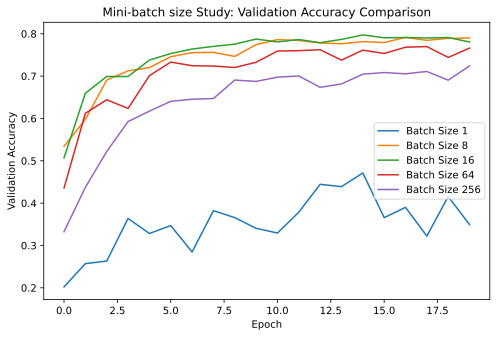

In [42]:
plt.figure(figsize=(8, 5))
plt.plot(batch_history_1["val_accs"], label="Batch Size 1")
plt.plot(batch_history_8["val_accs"], label="Batch Size 8")
plt.plot(batch_history_16["val_accs"], label="Batch Size 16")
plt.plot(batch_history_64["val_accs"], label="Batch Size 64")
plt.plot(batch_history_256["val_accs"], label="Batch Size 256")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Mini-batch size Study: Validation Accuracy Comparison")
plt.legend()
plt.show()